<a href="https://colab.research.google.com/github/kjmobile/lb2/blob/main/8_Ensemble_Random_Forest_and_Boosting_Late_Flights_all.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 8. Ensembles: Random Forest and Boosting

One decision tree is easy to read but easy to overfit. An **ensemble** combines many models into one prediction.

- **Bagging** (random forest): grow many trees **in parallel**, each on a different random sample of the flights,
  and let them vote.
- **Boosting** (AdaBoost, gradient boosting): grow small trees **one after another**, each one focusing on the
  mistakes of the trees before it.

Slides: W3.1, random forest (bagging), boosting, AdaBoost, gradient boosting.

> **Data.** The same 2,000 U.S. domestic flights from 2024 as in notebooks 6 and 7 (BTS on-time records, public data).
> `late` = 1 if the flight arrived 15+ minutes late.

> **Full version.** This notebook includes the code that draws every figure. The `_simple` version leaves that code out and shows the same figures as pictures.

## 1. Data and Two Single Trees to Beat

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

flights = pd.read_csv('https://raw.githubusercontent.com/kjmobile/lb2/main/data/flights_late_2024.csv')
X = flights.drop(columns='late')
y = flights['late']
train_X, test_X, train_y, test_y = train_test_split(X, y, test_size=0.2, random_state=320, stratify=y)
print('baseline (always guess "on time"):', round(1 - test_y.mean(), 3))

baseline (always guess "on time"): 0.792


In [2]:
full_tree = DecisionTreeClassifier(random_state=320).fit(train_X, train_y)     # grows until it stops
pruned_tree = DecisionTreeClassifier(max_depth=3, random_state=320).fit(train_X, train_y)

print('full tree,   test accuracy:', round(full_tree.score(test_X, test_y), 3))
print('pruned tree, test accuracy:', round(pruned_tree.score(test_X, test_y), 3))

full tree,   test accuracy: 0.785
pruned tree, test accuracy: 0.863


From notebook 6: the full tree overfits; the pruned tree (depth 3, chosen with care in notebook 7) does well.

## 2. Random Forest: Many Trees Vote

`RandomForestClassifier` grows 100 trees by default. Each tree sees a **bootstrap sample** (flights drawn at random
from the training set, with replacement, so some appear twice and others not at all) and, at each question, only
a random subset of the inputs. The forest's prediction is the average vote of its trees.

The trees are **not pruned**: each one overfits in its own way, and the vote cancels much of it out.

In [3]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=320, n_jobs=-1)
forest.fit(train_X, train_y)

print('train accuracy:', round(forest.score(train_X, train_y), 3))
print('test accuracy: ', round(forest.score(test_X, test_y), 3))
print('OOB accuracy:  ', round(forest.oob_score_, 3))

train accuracy: 1.0
test accuracy:  0.85
OOB accuracy:   0.861


A forest of 100 overfitted trees does much better on new flights than one overfitted tree, with no pruning by hand.

**OOB (out-of-bag) score.** Each bootstrap sample leaves out about 37% of the training flights. Each tree is scored
on the flights it never saw, so the forest gets a built-in validation score without a separate validation set.
It lands close to the test accuracy.

### Which inputs did the forest use?

In [4]:
importance = pd.DataFrame({'single pruned tree': pruned_tree.feature_importances_,
                           'random forest': forest.feature_importances_}, index=X.columns).round(3)
importance

,single pruned tree,random forest
month,0.000,0.089
dep_hour,0.000,0.102
distance,0.000,0.181
inbound_delay,0.834,0.441
turn_minutes,0.166,0.186


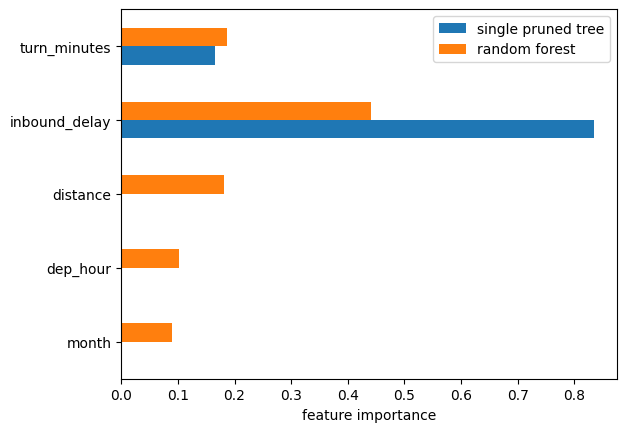

In [5]:
# Figure 1
importance.plot(kind='barh')
plt.xlabel('feature importance')
plt.show()

The pruned tree used only two inputs. The forest spreads importance across all five, because each tree is forced to
try different inputs. The incoming plane's delay still matters most. Part of the weight on distance, hour and month
comes from deep trees splitting on small differences, so read the smaller bars with care.

## 3. AdaBoost: Learn From Mistakes

AdaBoost starts with equal weights on all training flights and fits a **decision stump** (a tree with a single
question). Flights it gets wrong get more weight, and the next stump focuses on them. The final answer is a
weighted vote of all the stumps. By default `AdaBoostClassifier` uses 50 stumps.

In [6]:
from sklearn.ensemble import AdaBoostClassifier

ada = AdaBoostClassifier(n_estimators=50, random_state=320)
ada.fit(train_X, train_y)

print('train accuracy:', round(ada.score(train_X, train_y), 3))
print('test accuracy: ', round(ada.score(test_X, test_y), 3))

train accuracy: 0.865
test accuracy:  0.865


## 4. Gradient Boosting: Fit the Remaining Errors

Gradient boosting also adds trees one after another, but each new tree is fit to the **remaining errors** (the
residuals) of the trees so far. By default it adds 100 trees of depth 3, each one taking a small step
(`learning_rate=0.1`).

In [7]:
from sklearn.ensemble import GradientBoostingClassifier

boost = GradientBoostingClassifier(random_state=320)
boost.fit(train_X, train_y)

print('train accuracy:', round(boost.score(train_X, train_y), 3))
print('test accuracy: ', round(boost.score(test_X, test_y), 3))

train accuracy: 0.901


test accuracy:  0.858


## 5. Compare

In [8]:
results = pd.Series({'always "on time"': 1 - test_y.mean(),
                     'full tree': full_tree.score(test_X, test_y),
                     'pruned tree': pruned_tree.score(test_X, test_y),
                     'random forest': forest.score(test_X, test_y),
                     'AdaBoost': ada.score(test_X, test_y),
                     'gradient boosting': boost.score(test_X, test_y)}).round(3)
results

always "on time"     0.792
full tree            0.785
pruned tree          0.862
random forest        0.850
AdaBoost             0.865
gradient boosting    0.858
dtype: float64

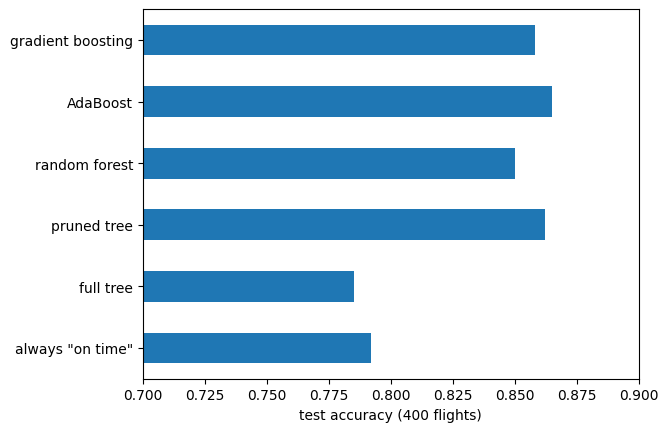

In [9]:
# Figure 2
results.plot(kind='barh', xlim=(0.7, 0.9))
plt.xlabel('test accuracy (400 flights)')
plt.show()

**What the comparison says.**

- Every ensemble is far better than the single full tree. That is the main gain: ensembles get good results
  **without** hand-tuning the depth.
- On this data the ensembles land close to the carefully pruned tree. Most of the signal sits in one input (how late
  the incoming plane is), and three questions already capture it. With more inputs that interact (weather, airport,
  crew connections), ensembles usually pull ahead of a single tree.
- On 400 test flights, one flight is 0.25 percentage points, so differences of a point or less are within luck.

### Your turn

The forest's trees are unpruned. Make each tree a little simpler by requiring at least **5 training flights** in every
final group (`min_samples_leaf`).

1. In the cell below, fill in the blanks (`___`) and run it.
2. Then finish this sentence:
   *With at least 5 flights per final group, the forest's test accuracy is ___ and its OOB accuracy is ___.*

<details><summary>Show answer</summary>

```python
forest_5 = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, oob_score=True, random_state=320, n_jobs=-1)
forest_5.fit(train_X, train_y)

print('test accuracy:', round(forest_5.score(test_X, test_y), 3))
print('OOB accuracy: ', round(forest_5.oob_score_, 3))
```

*With at least 5 flights per final group, the forest's test accuracy is **0.858** and its OOB accuracy is **0.864**. Slightly simpler trees help a little.*
</details>

In [ ]:
forest_5 = RandomForestClassifier(n_estimators=100, min_samples_leaf=___, oob_score=True, random_state=320, n_jobs=-1)
forest_5.___(train_X, train_y)

print('test accuracy:', round(forest_5.score(test_X, test_y), 3))
print('OOB accuracy: ', round(forest_5.oob_score_, 3))

## 6. Summary

| Model | How it combines trees | Test accuracy |
|---|---|---|
| Full tree | one tree, grown until it stops | about 0.79 (overfits) |
| Pruned tree | one tree, depth 3 | about 0.86 |
| Random forest | 100 unpruned trees vote (bagging) | about 0.85, OOB about 0.86 |
| AdaBoost | 50 stumps, each focusing on the previous mistakes | about 0.87 |
| Gradient boosting | 100 small trees, each fitting the remaining errors | about 0.86 |

---
# Challenge

1. Grow the forest to `n_estimators=500`. Does the test accuracy change? Does the OOB score?
2. Fit gradient boosting with `max_depth=2` and then `max_depth=5`. Which overfits more? (Compare train and test.)
3. Your manager asks for the model that operations agents can **explain** to a captain. Which model would you pick
   from section 5, and why?

In [11]:
# Your answer